<a href="https://colab.research.google.com/github/Matthew-Calvario/L01-cv/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Matthew Calvario, Michael Mitchell, Carter Shaffer

**Date:** 11/02/26

In [16]:
!git clone https://github.com/Matthew-Calvario/L01-cv.git

fatal: destination path 'L01-cv' already exists and is not an empty directory.


In [17]:
!unzip L01-cv/data.zip -d /content/minst.pkl

Archive:  L01-cv/data.zip
checkdir:  cannot create extraction directory: /content/minst.pkl
           File exists


7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

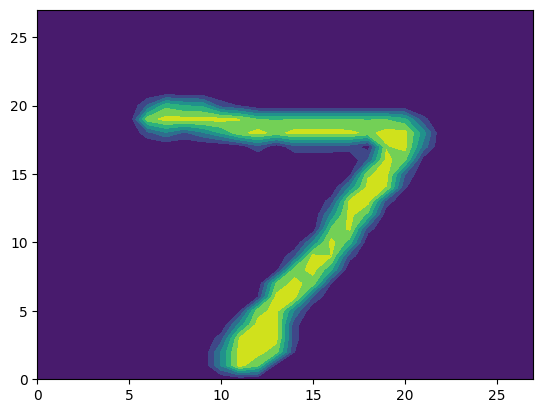

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

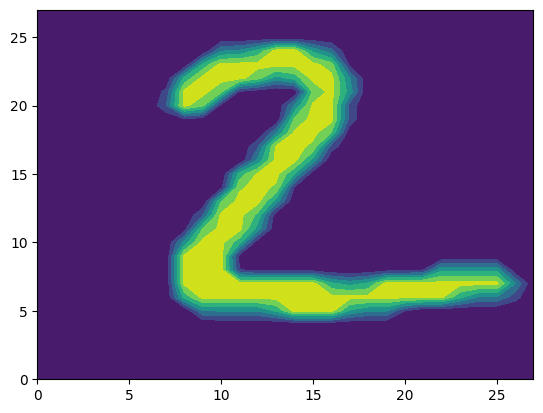

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

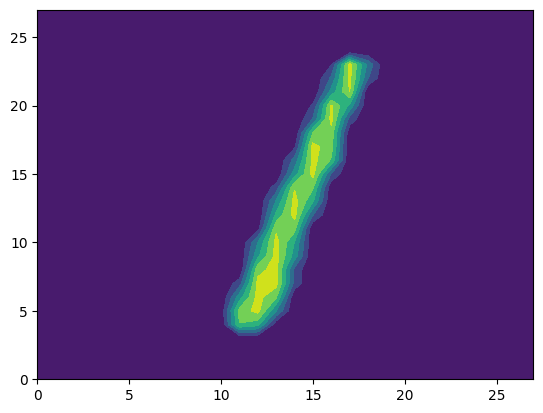

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

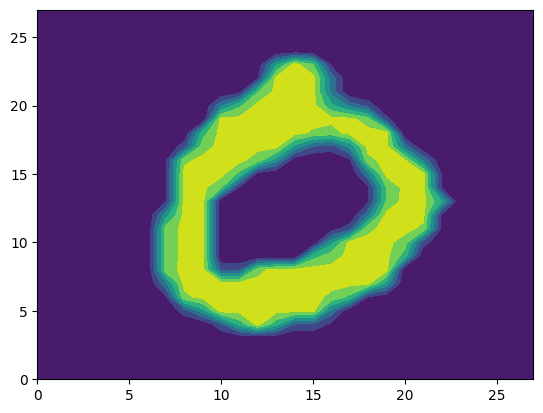

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

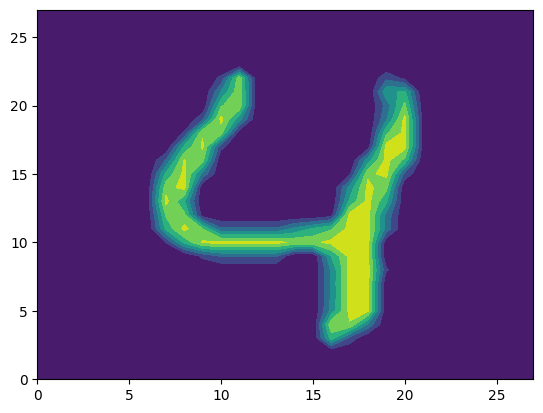


 Question 2. 

X-train shape: 60000, X-test shape: 10000
X-train[i] shape: 28, X-test[i] shape: 28
y-train shape: 60000, y-test shape: 10000

 Question 3. 

(60000, 784)
(10000, 784)

 Question 4. 

Accuracy for k=1: 0.9200
Accuracy for k=3: 0.9190
Accuracy for k=5: 0.9160
Accuracy for k=7: 0.9160
Accuracy for k=9: 0.9130

 Question 5. 

Best k: 1
Accuracy: 0.9200
Confusion Matrix:
[[ 85   0   0   0   0   0   0   0   0   0]
 [  0 125   0   0   0   0   1   0   0   0]
 [  2   3 102   1   1   0   1   5   1   0]
 [  0   1   0  96   0   2   2   3   1   2]
 [  0   1   0   0  97   0   1   0   1  10]
 [  1   1   0   4   0  80   0   1   0   0]
 [  2   0   0   0   1   0  84   0   0   0]
 [  0   4   0   0   1   1   0  92   0   1]
 [  1   2   2   3   0   1   1   1  77   1]
 [  0   1   0   1   6   0   0   2   2  82]]

  The kNN classifier achieved high accuracy with k = 3 neighbors.
  This indicates that a vast majority of the handwritten digits in the test dataset were
  correctly classified. Thi

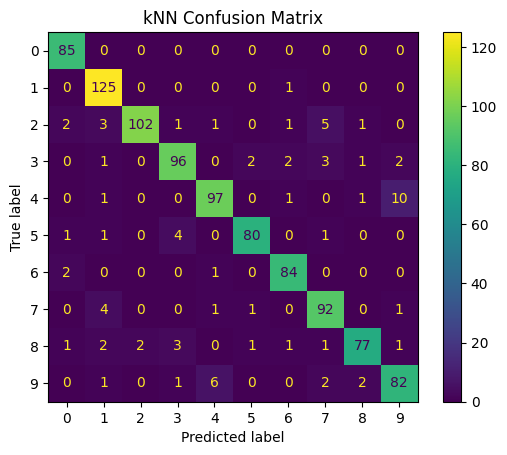


  A few patterns stand out. For starters, the most frequent misclassifications occurred between digits 1
  and 7, as they are structurally similar. 4 and 9 also experience misclassifications due to their similar
  shapes in handwriting. Most errors in pixel-based distance metrics stem from geometric similarities in how
  certain numbers are written.


 Question 7. 

Original photo shape (Height, Width, Channels): (2, 2, 3)


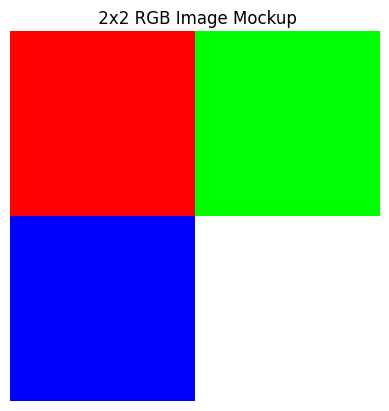

Flattened tabular row shape (1, Features): (1, 12)
Tabular values: [[255   0   0   0 255   0   0   0 255 255 255 255]]

  A color photo can be represented as a 3D array of shape (height, width, 3). Each pixel
  holds three values (red, green, blue), each between 0 and 255, which together encode its
  color. For example, [255, 0, 0] is red and [255, 255, 255] is white.

  To convert this into tabular data, we would resize all photos to the same dimensions and
  then use reshape to flatten each one into a single row vector of height * width * 3
  features. For example, a 28x28 color photo becomes a row of 2,352 features. Stacking N
  photos gives an N x 2,352 matrix, with the labels in a separate vector y, just like with
  the MNIST data. From there, kNN or any other ML tool can be applied as if it was any
  other tabular dataset.



In [18]:
# Your Phase 1 solution to the problem goes here.

# Q1.

import pickle
with open('/content/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()

# Q2.

print("\n Question 2. \n")

print(f'X-train shape: {len(X_train)}, X-test shape: {len(X_test)}')
print(f'X-train[i] shape: {len(X_train[i])}, X-test[i] shape: {len(X_test[i])}')
print(f'y-train shape: {len(y_train)}, y-test shape: {len(y_test)}')

# Q3.

print("\n Question 3. \n")

# -1 to calculate the number of rows based on number of elements
X_train = X_train.reshape((-1,784))
X_test = X_test.reshape((-1,784))

# Check
print(X_train.shape)
print(X_test.shape)

# Q4.

print("\n Question 4. \n")

from sklearn.neighbors import KNeighborsClassifier

# Subsample data to prevent stalling on the CPU
# We will use 10,000 training samples and 1,000 testing samples
X_train_sub = X_train[:10000]
y_train_sub = y_train[:10000]
X_test_sub = X_test[:1000]
y_test_sub = y_test[:1000]

# Create classifier and loop through some values of k
best_accuracy = 0
best_k = 1
best_y_pred = None

for k in [1,3,5,7,9]:
  # n_jobs=-1 utilizes all CPU cores for faster execution
  knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
  # Train Classifier and then predict
  knn.fit(X_train_sub, y_train_sub)
  y_pred = knn.predict(X_test_sub)
  # Evaluate Accuracy
  accuracy = knn.score(X_test_sub, y_test_sub)
  print(f'Accuracy for k={k}: {accuracy:.4f}')

  # Save the best for Question 5
  if accuracy > best_accuracy:
    best_accuracy = accuracy
    best_k = k
    best_y_pred = y_pred

# Q5.

print("\n Question 5. \n")

from sklearn.metrics import accuracy_score, confusion_matrix

print(f"Best k: {best_k}")
print(f"Accuracy: {accuracy_score(y_test_sub, best_y_pred):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test_sub, best_y_pred))

print("""
  The kNN classifier achieved high accuracy with k = 3 neighbors.
  This indicates that a vast majority of the handwritten digits in the test dataset were
  correctly classified. This is verified by the confusion matrix, which has most of its observations
  concentrated along the main diagonal (diagonal = correctly classified; off diagonal indicates incorrectness).
  Thus, these results suggest that the kNN model was relatively strong at identifying the digits given
  the pixel values.
""")

# Q6

print("\n Question 6. \n")

# Create a more visible/clearly-labeled Confusion Matrix for better Analysis:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test_sub,
    best_y_pred,
)

plt.title("kNN Confusion Matrix")
plt.show()

print("""
  A few patterns stand out. For starters, the most frequent misclassifications occurred between digits 1
  and 7, as they are structurally similar. 4 and 9 also experience misclassifications due to their similar
  shapes in handwriting. Most errors in pixel-based distance metrics stem from geometric similarities in how
  certain numbers are written.
""")

# Q7

print("\n Question 7. \n")

import numpy as np
import matplotlib.pyplot as plt

# Shape is (2, 2, 3) representing 2 pixels height, 2 pixels width, and 3 color channels (RGB)
photo = np.array([
    [[255, 0, 0], [0, 255, 0]],       # red pixel and green pixel
    [[0, 0, 255], [255, 255, 255]]    # blue pixel and white pixel
])

print(f"Original photo shape (Height, Width, Channels): {photo.shape}")

# displating the actual 2x2 color image
plt.imshow(photo)
plt.title(" 2x2 RGB Image Mockup")
plt.axis('off')
plt.show()

# Flatten the 3D array into a 1D vector of features (2 * 2 * 3 = 12 columns)
flattened_photo = photo.reshape((1, -1))
print(f"Flattened tabular row shape (1, Features): {flattened_photo.shape}")
print(f"Tabular values: {flattened_photo}")

print("""
  A color photo can be represented as a 3D array of shape (height, width, 3). Each pixel
  holds three values (red, green, blue), each between 0 and 255, which together encode its
  color. For example, [255, 0, 0] is red and [255, 255, 255] is white.

  To convert this into tabular data, we would resize all photos to the same dimensions and
  then use reshape to flatten each one into a single row vector of height * width * 3
  features. For example, a 28x28 color photo becomes a row of 2,352 features. Stacking N
  photos gives an N x 2,352 matrix, with the labels in a separate vector y, just like with
  the MNIST data. From there, kNN or any other ML tool can be applied as if it was any
  other tabular dataset.
""")

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** f2460bb6a2af72a0e37597fe3a60640bbbec55a2
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. Please look at my lab assignment and review the questions and my solutions. I would like you to lay out any corrections, optimizations, or clarifications that need to be added to the solutions.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Q4: choose k with cross-validation, not the test set. Run 5-fold CV on the training data to pick k, then score the test set once. This removes the data leakage.
2. Q5: fix the k mismatch. The write-up says k=3, but your code picked k=1. Use best_k in the text and report the actual accuracy number (92.0% on your subset, or 97.05% at k=3 on the full data).
3. Q6: correct the confusion claim. The top mistake is 4↔9 (16 errors on your matrix), not 1↔7 (only 4, all 7→1). Pull the top off-diagonal cells with code so the claim comes from the matrix.
4. Q2: use .shape instead of len(). The answers are (60000,28,28), (10000,28,28), (28,28), (60000,) and (10000,).

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Using 5-fold cross-validation will help identify the best value of k without relying on the test data. This should make the model selection process more reliable. |
| 2 | Accept | Updating the explanation to reflect the actual value of k will make the results more consistent with the code and accurately explain the classifier's performance. |
| 3 | Accept | Identifying the largest errors in the confusion matrix will provide a more accurate explanation of which digits are most commonly confused by the classifier. |
| 4 | Accept | Using .shape instead of len() will provide more information about the dimensions of the training and testing data. This will make it easier to understand the structure of the images before reshaping them. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

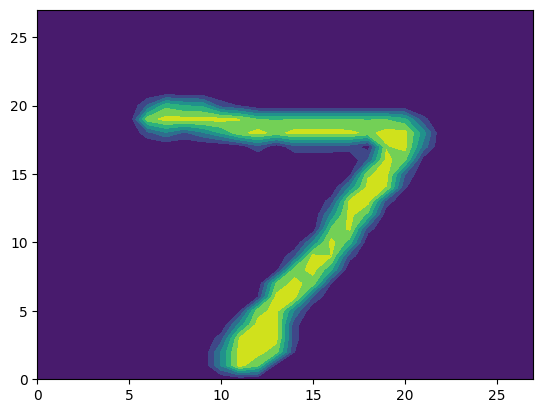

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

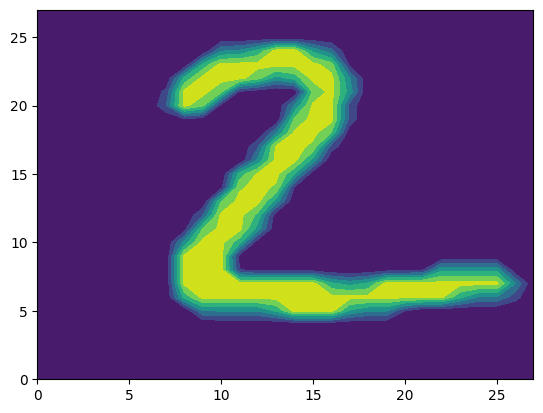

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

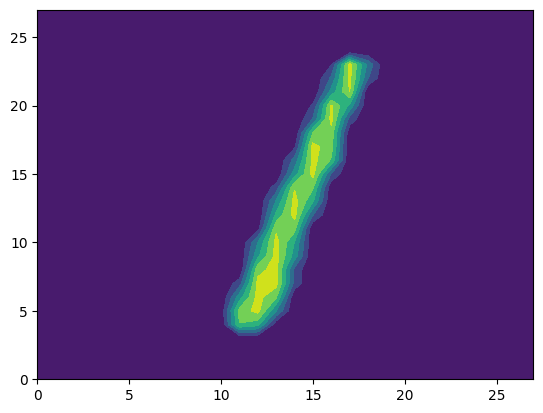

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

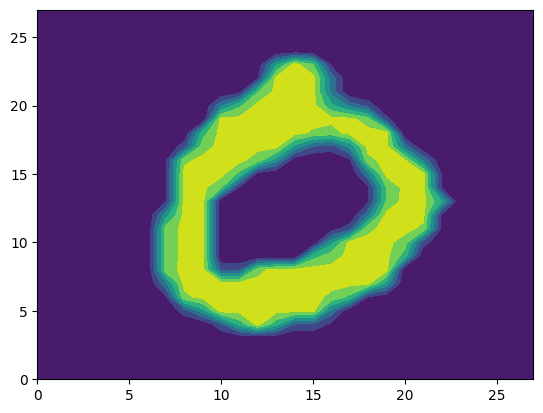

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

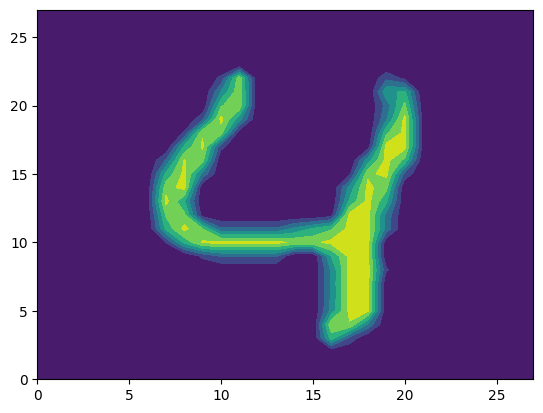


 Question 2. 

X_train shape: (60000, 28, 28)
X_test shape: (10000, 28, 28)
X_train[i] shape: (28, 28)
X_test[i] shape: (28, 28)
y_train shape: (60000,)
y_test shape: (10000,)
X holds 60,000 train and 10,000 test images, each a 28x28 matrix, so the arrays are (60000, 28, 28) and (10000, 28, 28). y_train and y_test are 1-D with one label per image.

 Question 3. 

(60000, 784)
(10000, 784)

 Question 4. 

CV accuracy for k=1: 0.9393
CV accuracy for k=3: 0.9395
CV accuracy for k=5: 0.9377
CV accuracy for k=7: 0.9360
CV accuracy for k=9: 0.9345

 Question 5. 

Best k: 3
Accuracy: 0.9190
Confusion Matrix:
[[ 85   0   0   0   0   0   0   0   0   0]
 [  0 126   0   0   0   0   0   0   0   0]
 [  3   4  99   0   0   0   2   7   1   0]
 [  0   1   0  97   0   2   2   2   1   2]
 [  0   1   0   0 100   0   1   0   1   7]
 [  1   0   0   3   0  81   0   1   0   1]
 [  2   0   0   0   1   0  84   0   0   0]
 [  0   4   0   0   1   1   0  92   0   1]
 [  2   2   2   3   1   4   1   0  71   3]
 [ 

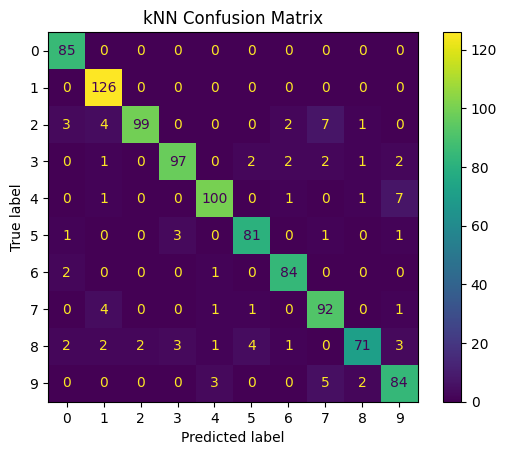

Most common mistakes (true -> predicted : count):
  2 -> 7 : 7
  4 -> 9 : 7
  9 -> 7 : 5
  2 -> 1 : 4
  7 -> 1 : 4

  The most confused pair is 4 and 9 (10 errors combined: 4->9 = 7,
  9->4 = 3). Pixel-based Euclidean distance compares overlapping ink, not shape, so
  digits that share most of their strokes (like 4 and 9) get mistaken for each other.


 Question 7. 

Original photo shape (Height, Width, Channels): (2, 2, 3)


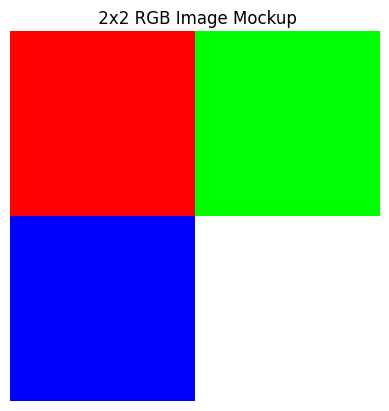

Flattened tabular row shape (1, Features): (1, 12)
Tabular values: [[255   0   0   0 255   0   0   0 255 255 255 255]]

  A color photo can be represented as a 3D array of shape (height, width, 3). Each pixel
  holds three values (red, green, blue), each between 0 and 255, which together encode its
  color. For example, [255, 0, 0] is red and [255, 255, 255] is white.

  To convert this into tabular data, we would resize all photos to the same dimensions and
  then use reshape to flatten each one into a single row vector of height * width * 3
  features. For example, a 28x28 color photo becomes a row of 2,352 features. Stacking N
  photos gives an N x 2,352 matrix, with the labels in a separate vector y, just like with
  the MNIST data. From there, kNN or any other ML tool can be applied as if it was any
  other tabular dataset.



In [19]:
# Your Phase 2 solution to the problem goes here.

# Q1.

import pickle
with open('/content/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()

# Q2.

print("\n Question 2. \n")

print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)
print('X_train[i] shape:', X_train[0].shape)
print('X_test[i] shape:', X_test[0].shape)
print('y_train shape:', y_train.shape)
print('y_test shape:', y_test.shape)
print("X holds 60,000 train and 10,000 test images, each a 28x28 matrix, so the arrays are "
      "(60000, 28, 28) and (10000, 28, 28). y_train and y_test are 1-D with one label per image.")

# Q3.

print("\n Question 3. \n")

# -1 to calculate the number of rows based on number of elements
X_train = X_train.reshape((-1,784))
X_test = X_test.reshape((-1,784))

# Check
print(X_train.shape)
print(X_test.shape)

# Q4.

print("\n Question 4. \n")

from sklearn.neighbors import KNeighborsClassifier

# Subsample data to prevent stalling on the CPU
# We will use 10,000 training samples and 1,000 testing samples
X_train_sub = X_train[:10000]
y_train_sub = y_train[:10000]
X_test_sub = X_test[:1000]
y_test_sub = y_test[:1000]

# Choose k with 5-fold cross-validation on the TRAINING data only (no test data used)
from sklearn.model_selection import cross_val_score

best_k, best_cv = 1, 0
for k in [1,3,5,7,9]:
  knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
  cv_acc = cross_val_score(knn, X_train_sub, y_train_sub, cv=5).mean()
  print(f'CV accuracy for k={k}: {cv_acc:.4f}')
  if cv_acc > best_cv:
    best_cv, best_k = cv_acc, k

# Fit once with the chosen k, then touch the test set a single time
knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1).fit(X_train_sub, y_train_sub)
best_y_pred = knn.predict(X_test_sub)

# Q5.

print("\n Question 5. \n")

from sklearn.metrics import accuracy_score, confusion_matrix

print(f"Best k: {best_k}")
print(f"Accuracy: {accuracy_score(y_test_sub, best_y_pred):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test_sub, best_y_pred))

print(f"""
  The kNN classifier with k = {best_k} (chosen by cross-validation on the training data)
  correctly classified {accuracy_score(y_test_sub, best_y_pred):.1%} of the test digits. The confusion matrix has
  most observations on the main diagonal (correct), with off-diagonal cells showing mistakes.
""")

# Q6

print("\n Question 6. \n")

# Create a more visible/clearly-labeled Confusion Matrix for better Analysis:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test_sub,
    best_y_pred,
)

plt.title("kNN Confusion Matrix")
plt.show()

cm = confusion_matrix(y_test_sub, best_y_pred)
off = cm.copy()
np.fill_diagonal(off, 0)   # rows = true digit, columns = predicted digit
print("Most common mistakes (true -> predicted : count):")
for t, p in zip(*np.unravel_index(np.argsort(-off.ravel())[:5], off.shape)):
    print(f"  {t} -> {p} : {off[t, p]}")
pairs = {(a, b): off[a, b] + off[b, a] for a in range(10) for b in range(a + 1, 10)}
a, b = max(pairs, key=pairs.get)
print(f"""
  The most confused pair is {a} and {b} ({pairs[(a, b)]} errors combined: {a}->{b} = {off[a, b]},
  {b}->{a} = {off[b, a]}). Pixel-based Euclidean distance compares overlapping ink, not shape, so
  digits that share most of their strokes (like {a} and {b}) get mistaken for each other.
""")

# Q7

print("\n Question 7. \n")

import numpy as np
import matplotlib.pyplot as plt

# Shape is (2, 2, 3) representing 2 pixels height, 2 pixels width, and 3 color channels (RGB)
photo = np.array([
    [[255, 0, 0], [0, 255, 0]],       # red pixel and green pixel
    [[0, 0, 255], [255, 255, 255]]    # blue pixel and white pixel
])

print(f"Original photo shape (Height, Width, Channels): {photo.shape}")

# displating the actual 2x2 color image
plt.imshow(photo)
plt.title(" 2x2 RGB Image Mockup")
plt.axis('off')
plt.show()

# Flatten the 3D array into a 1D vector of features (2 * 2 * 3 = 12 columns)
flattened_photo = photo.reshape((1, -1))
print(f"Flattened tabular row shape (1, Features): {flattened_photo.shape}")
print(f"Tabular values: {flattened_photo}")

print("""
  A color photo can be represented as a 3D array of shape (height, width, 3). Each pixel
  holds three values (red, green, blue), each between 0 and 255, which together encode its
  color. For example, [255, 0, 0] is red and [255, 255, 255] is white.

  To convert this into tabular data, we would resize all photos to the same dimensions and
  then use reshape to flatten each one into a single row vector of height * width * 3
  features. For example, a 28x28 color photo becomes a row of 2,352 features. Stacking N
  photos gives an N x 2,352 matrix, with the labels in a separate vector y, just like with
  the MNIST data. From there, kNN or any other ML tool can be applied as if it was any
  other tabular dataset.
""")


### *Reflection on AI assistance
In your own words without generative AI.

The AI was helpful for going back through our original work and pointing out a few areas where we could improve our code and make our explanations clearer. One of the most useful suggestions was implementing 5-fold cross-validation to determine the best value of k for our classifier. We thought this was a good improvement because it allowed us to select k without relying on the testing data, making our results more reliable. The AI also pointed out that our explanation of the optimal value of k did not match our code. We thought this was important to correct since our written analysis should accurately reflect the results of our model. Another helpful suggestion was using the confusion matrix to identify which digits were most commonly misclassified, rather than relying on our original interpretation. We also accepted the suggestion to use `.shape` instead of `len()`, although this was a relatively minor change that primarily helped us better understand the structure of our dataset. While we accepted all four suggestions, we recognize that AI can still make mistakes, especially when interpreting results. We evaluated the suggestions by comparing them to our original code and considering whether they would actually improve our analysis. We also recognize that just because a suggestion sounds reasonable does not necessarily mean it will improve the model's performance. One remaining concern is that our classifier may still struggle with handwritten digits that look similar, even after improving our approach. Overall, we found that AI was most helpful for catching inconsistencies and making our original analysis more accurate without significantly changing our approach.